# Greek Air Traffic: Analysis

Monthly passengers per Greek airport (Eurostat `avia_paoa`).

## 1. Load and clean the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("data/greek_airports_passengers.csv")

# Keep only the columns we need and give them simple names
df = raw[["rep_airp", "TIME_PERIOD", "OBS_VALUE"]].rename(columns={
    "rep_airp": "code",
    "TIME_PERIOD": "month",
    "OBS_VALUE": "passengers",
})

# "EL_LGAV" -> "LGAV" (the ICAO airport code)
df["code"] = df["code"].str.replace("EL_", "")

# Turn "2025-07" into a real date, and keep the year separately
df["month"] = pd.to_datetime(df["month"])
df["year"] = df["month"].dt.year

df.head()

,code,month,passengers,year
0,LG03,1999-01-01,3135,1999
1,LG03,1999-02-01,2808,1999
2,LG03,1999-03-01,5011,1999
3,LG03,1999-04-01,16093,1999
4,LG03,1999-05-01,62820,1999


In [2]:
# Readable airport names. Codes not listed here keep their code as name.
airport_names = {
    "LGAV": "Athens", "LGTS": "Thessaloniki", "LGIR": "Heraklion",
    "LGRP": "Rhodes", "LGSA": "Chania", "LGKR": "Corfu",
    "LGKO": "Kos", "LGSR": "Santorini", "LGZA": "Zakynthos",
    "LGMK": "Mykonos", "LGKF": "Kefalonia", "LGPZ": "Preveza",
    "LGSK": "Skiathos", "LGKL": "Kalamata", "LGMT": "Mytilene",
    "LGSM": "Samos", "LGHI": "Chios", "LGIO": "Ioannina",
    "LGAL": "Alexandroupoli", "LGKV": "Kavala", "LGPA": "Paros",
    "LGNX": "Naxos", "LGML": "Milos", "LGKP": "Karpathos",
    "LGLM": "Lemnos", "LGBL": "Volos", "LGRX": "Araxos",
    "LGSO": "Syros", "LGST": "Sitia", "LGLE": "Leros",
    "LGIK": "Ikaria", "LGKC": "Kythira", "LGKA": "Kastoria",
    "LGKZ": "Kozani", "LGPL": "Astypalaia", "LGKS": "Kasos",
    "LGKJ": "Kastellorizo", "LGKY": "Kalymnos", "LGSY": "Skyros",
    "LGAT": "Athens (old Hellinikon)",
}
df["airport"] = df["code"].map(airport_names).fillna(df["code"])

## 2. Which airports carry the most passengers?

We use 2025, the latest full year in the data.

In [3]:
year = 2025

# Sum the 12 months of the year for each airport, biggest first
totals = (
    df[df["year"] == year]
    .groupby("airport")["passengers"]
    .sum()
    .sort_values(ascending=False)
)

# Share of all Greek passengers that each airport handles
share = (totals / totals.sum() * 100).round(1)

pd.DataFrame({"passengers": totals, "share_%": share}).head(10)

,passengers,share_%
airport,,
Athens,33735304,40.4
Heraklion,10020427,12.0
Thessaloniki,7951983,9.5
Rhodes,7078253,8.5
Corfu,4608966,5.5
Chania,4148103,5.0
Kos,3172820,3.8
Santorini,2413526,2.9
Zakynthos,2280931,2.7


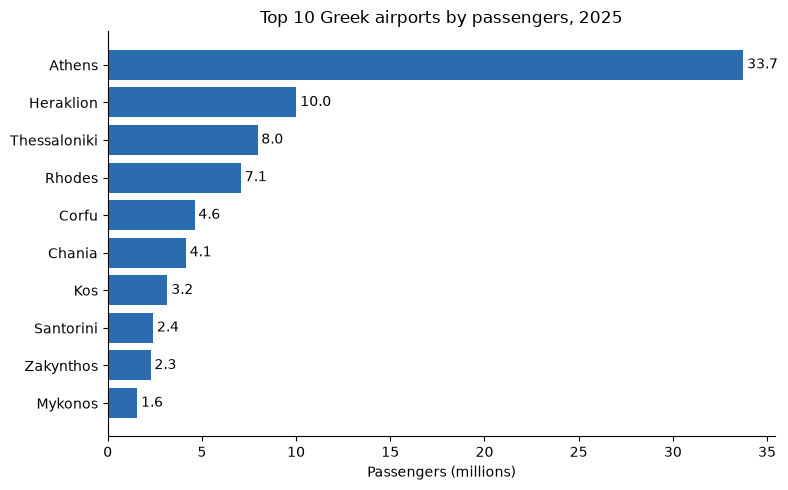

In [4]:
top10 = totals.head(10) / 1_000_000  # in millions

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index[::-1], top10.values[::-1], color="#2b6cb0")
ax.set_xlabel("Passengers (millions)")
ax.set_title(f"Top 10 Greek airports by passengers, {year}")
ax.spines[["top", "right"]].set_visible(False)

# Write the value at the end of each bar
for i, value in enumerate(top10.values[::-1]):
    ax.text(value + 0.2, i, f"{value:.1f}", va="center")

plt.tight_layout()
plt.show()